In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
student_data=pd.read_csv('student_performance_dataset.csv')
print(student_data.head())

  Student_ID  Gender  Study_Hours_per_Week  Attendance_Rate  Past_Exam_Scores  \
0       S147    Male                    31        68.267841                86   
1       S136    Male                    16        78.222927                73   
2       S209  Female                    21        87.525096                74   
3       S458  Female                    27        92.076483                99   
4       S078  Female                    37        98.655517                63   

  Parental_Education_Level Internet_Access_at_Home Extracurricular_Activities  \
0              High School                     Yes                        Yes   
1                      PhD                      No                         No   
2                      PhD                     Yes                         No   
3                Bachelors                      No                         No   
4                  Masters                      No                        Yes   

   Final_Exam_Score Pass_F

In [5]:
X=student_data['Past_Exam_Scores'].to_numpy()
Y=student_data['Final_Exam_Score'].to_numpy()
print(X.shape)
print(Y.shape)

(708,)
(708,)


In [6]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [7]:
print(x_train.shape)

(566,)


In [8]:
def compute_prediction(x,w,b):
    y_prediction=w*x+b
    return y_prediction
w=0.5
b=1
prediction=compute_prediction(x_train,w,b)
print(prediction[:10])

[48.  47.  45.  29.  50.  29.5 38.  42.  43.  45. ]


In [9]:

def compute_cost(x,y,w,b):
    y_prediction=compute_prediction(x,w,b)
    square_error=(y_prediction-y)**2
    total_square_error=np.sum(square_error)
    m=len(y_prediction)
    cost=total_square_error/(2*m)
    return cost

In [10]:
initial_w = 0
initial_b = 0

cost = compute_cost(x_train, y_train, initial_w, initial_b)

print("Initial cost:", cost)

Initial cost: 1754.1775618374559


In [11]:
def compute_gradient(x,y,w,b):
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    m=len(y_pred)
    dj_dw=np.sum(error*x)/m
    dj_db=np.sum(error)/m
    return dj_dw, dj_db

In [12]:
dj_dw, dj_db = compute_gradient(x_train, y_train, 0, 0)

print("dj_dw:", dj_dw)
print("dj_db:", dj_db)

dj_dw: -4621.7420494699645
dj_db: -58.84628975265018


In [13]:
def update_parameters(x,y,w,b,alpha,iteration):
    cost_history=[]
    for i in range(iteration):
        dj_dw,dj_db=compute_gradient(x,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        cost=compute_cost(x,y,w,b)
        cost_history.append(cost)
    return w,b,cost_history

In [14]:
# Calculate using training data only
mean = np.mean(x_train)
std = np.std(x_train)

# Standardize training and testing data
X_train_norm = (x_train - mean) / std
X_test_norm = (x_test - mean) / std
w_initial = 0
b_initial = 0

w_final, b_final, cost_history = update_parameters(
    X_train_norm,
    y_train,
    w_initial,
    b_initial,
    alpha=0.01,
    iteration=1000
)

print("Final w:", w_final)
print("Final b:", b_final)
print("Final cost:", cost_history[-1])

Final w: 3.3261117181386965
Final b: 58.843749284916065
Final cost: 17.202669032286614


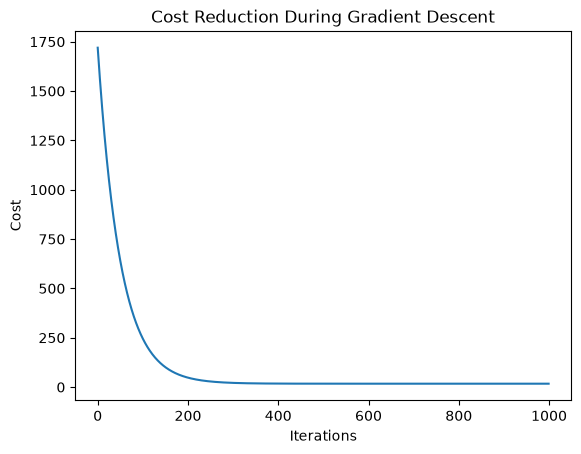

In [15]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction During Gradient Descent")
plt.show()

In [16]:
y_pred = compute_prediction(X_test_norm, w_final, b_final)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

MAE: 4.795782324725542
RMSE: 5.758977176489998
R2: 0.22045286613555914


In [17]:
w_original = w_final / std
b_original = b_final - w_original * mean

print("Original w:", w_original)
print("Original b:", b_original)

Original w: 0.22923600793645396
Original b: 41.027737353614526


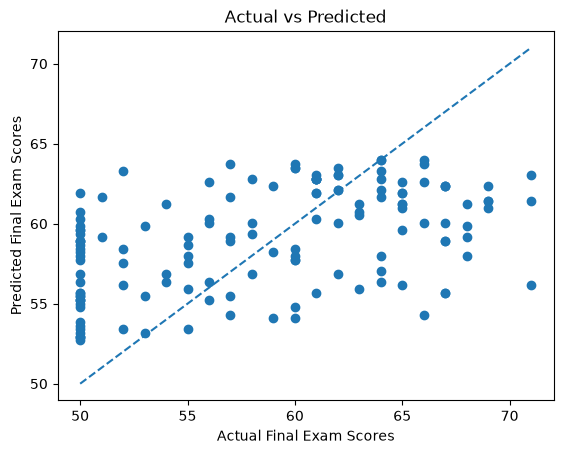

In [18]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Final Exam Scores")
plt.ylabel("Predicted Final Exam Scores")
plt.title("Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()